# 較正後チャネルの数値収束：$\bar n=4$

**目的**：本文の較正後振幅を固定し、フォノン次元、時間依存係数の
サンプル数、ODE 積分精度を変えて、Pauli 近似の誤差と Bell 生存確率の安定性を調べる。
各条件で 16 入力の QPT を再計算する。

この Notebook は**未実行**で配布する。計算するときは **RUN_QPT = True**
にして上から実行する。既定の False では新しい時間発展を行わず、
この Notebook の互換キャッシュだけを読む。数値結果・図・判定は実行後に生成される。

- 全条件で $A,\delta,T,\eta,\bar n$ と物理的ノイズ率を固定し、再較正しない。
- 主解析は CPTP 射影後。射影前の行列・指標・射影による変化も保存する。
- 既存の Hamiltonian・散逸項・入力状態・QPT 関数を再利用する。
  積分精度は Notebook 内の MESolver に明示的に渡し、既存モジュールを変更しない。
- $\bar n=4$ での検証であり、他の温度や有限 LD 展開の物理的妥当性を保証しない。

## 1. 環境と実行設定

QuTiP **5 系**、NumPy、SciPy、pandas、Matplotlib、CVXPY、SCS が必要。
既存の pauli_twirl_channel_distance.ipynb と同じ Python 環境を使用できる。
依存関係は自動インストールしない。

各条件の 16 入力は既定で 4 プロセスに分配する。
fork が使えない環境では逐次実行する。メモリ不足の場合は WORKERS = 1 にする。

In [9]:
from pathlib import Path
import os
import sys
import json
import hashlib
import time
import platform
import multiprocessing as mp
from functools import lru_cache
from concurrent.futures import ProcessPoolExecutor, as_completed
from importlib import metadata

# 既に NumPy がロード済みの場合は、カーネル再起動を推奨。
for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
             "VECLIB_MAXIMUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ.setdefault(name, "1")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import qutip as qp
import cvxpy as cp
from IPython.display import display, Markdown

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "ms_gate_functions.py").is_file()), None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("プロジェクトのルート、またはその配下で開いてください。")
sys.path.insert(0, str(PROJECT_ROOT))
import ms_gate_functions as mg
import drive_calibration_qpt_analysis as qpt
import pauli_channel_distance as pcd

if int(qp.__version__.split(".")[0]) != 5:
    raise RuntimeError("この Notebook は既存実装と同じ QuTiP 5 系を対象とします。")
if "SCS" not in cp.installed_solvers():
    raise RuntimeError("CVXPY から SCS を利用できる環境を選んでください。")

RUN_QPT = True                 # True: 未計算の QPT を実行
FORCE_QPT = False               # True は RUN_QPT=True の場合だけ有効
FORCE_ANALYSIS = False          # 時間発展は再利用し、後処理・SDP のみ再計算
WORKERS = 4
CASE_IDS_TO_RUN = None          # None: 全条件。例: ["baseline", "grid_1000"]
OUTPUT_ROOT = PROJECT_ROOT / "results" / "calibrated_channel_convergence_nbar4"
NOTEBOOK_PATH = PROJECT_ROOT / "calibrated_channel_convergence_nbar4.ipynb"
CPTP_TOL = 1e-11
CPTP_MAX_ITERATIONS = 5000
RAW_TRACE_TOL = 1e-8
PROJECTION_DISTANCE_TOL = 1e-6
SDP_OPTIONS = dict(
    solver="SCS", solver_tolerance=1e-8, gap_atol=1e-9, gap_rtol=1e-6,
)
VERSIONS = {
    name: metadata.version(name)
    for name in ("numpy", "scipy", "qutip", "pandas", "matplotlib", "cvxpy", "scs")
}
VERSIONS["python"] = platform.python_version()
assert WORKERS >= 1
assert not FORCE_QPT or RUN_QPT, "FORCE_QPT=True には RUN_QPT=True が必要です。"
display(pd.Series(VERSIONS, name="version").to_frame())


,version
numpy,1.26.4
scipy,1.13.0
qutip,5.0.4
pandas,2.2.2
matplotlib,3.8.4
cvxpy,1.6.5
scs,3.3.1
python,3.9.6


## 2. 既存の較正点と物理パラメータ

振幅は元の較正キャッシュの A_calibrated を優先し、CSV の振幅比とも照合する。
他のパラメータは本文のデータを準備した manifest から読む。
旧データは新計算の代わりにせず、基準設定での再現性確認だけに使う。

use_full_order=True は本プロジェクトの相対 $O(\eta^2)$ の側帯補正であり、
全次数の光学 Hamiltonian ではない。散乱率を含めて物理的ノイズ率を固定する。

In [10]:
SOURCE_DIR = PROJECT_ROOT / "results" / "pauli_twirl_channel_distance" / "inputs"
SOURCE_TABLE = SOURCE_DIR / "channel_comparison_long.csv"
SOURCE_MANIFEST = SOURCE_DIR / "preparation_manifest.json"
LEGACY_PROJECTED = SOURCE_DIR / "projected_chi_before_after.npz"
NBAR = 4.0

source_table = pd.read_csv(SOURCE_TABLE)
selected = source_table.loc[
    np.isclose(source_table["n_bar"], NBAR) & source_table["condition"].eq("after")
]
if len(selected) != 1:
    raise ValueError("nbar=4, after の較正結果が一意に見つかりません。")
source_row = selected.iloc[0]
source_params = json.loads(SOURCE_MANIFEST.read_text())["new_simulation_params"]
calibration_path = Path(source_row["source_path"])
if not calibration_path.is_absolute():
    calibration_path = PROJECT_ROOT / calibration_path
if not calibration_path.is_file() and "results" in calibration_path.parts:
    parts = calibration_path.parts
    calibration_path = PROJECT_ROOT.joinpath(*parts[parts.index("results"):])
calibration_meta = {}
if calibration_path.is_file():
    with np.load(calibration_path, allow_pickle=False) as archive:
        calibration_meta = json.loads(archive["metadata_json"].item())
else:
    print("元の較正キャッシュがないため、manifest と CSV の振幅比を使います。")

A0 = float(source_params["A"])
A_FIXED = float(calibration_meta.get("A_calibrated", A0 * float(source_row["A_factor"])))
np.testing.assert_allclose(
    A_FIXED / A0, float(source_row["A_factor"]), rtol=1e-12, atol=1e-14
)
PHYSICS = {
    key: float(source_params[key])
    for key in ("delta", "rho0", "t_gate_phys", "heating_rate_phys",
                "dephasing_rate_phys", "T2_star", "rayleigh_rate_phys",
                "raman_rate_phys", "eta")
}
PHYSICS.update(
    A=A_FIXED, n_bar=NBAR, use_full_order=True,
    t_gate_sim=float(2 * np.pi / abs(PHYSICS["delta"])),
    target_phi=float(np.pi / 4), error_channel_convention="undo_before_actual",
    scattering_scales_with_intensity=False,
)
for key in ("laser_intensity_fluctuation", "laser_detuning_fluctuation",
            "laser_rotation_angle_fluctuation"):
    if float(source_params[key]) != 0.0:
        raise ValueError("この検証は準静的レーザー揺らぎを含まない較正点用です。")
if not bool(source_params["use_full_order"]):
    raise ValueError("参照 manifest の Hamiltonian が本文の設定と異なります。")

N_BASE = int(mg.estimate_phonon_dim(NBAR, 2 * abs(A_FIXED / PHYSICS["delta"])))
if "phonon_dim" in calibration_meta and N_BASE != int(calibration_meta["phonon_dim"]):
    raise ValueError("既存の打ち切り次元と現在の heuristic が一致しません。")
labels, paulis = pcd.pauli_basis()
II, XX, IX, XI = [labels.index(s) for s in ("II", "XX", "IX", "XI")]
bell_vectors = {
    "phi_plus": np.array([1, 0, 0, 1], dtype=complex) / np.sqrt(2),
    "psi_minus": np.array([0, 1, -1, 0], dtype=complex) / np.sqrt(2),
}
BELL_STATES = {name: np.outer(v, v.conj()) for name, v in bell_vectors.items()}
LEGACY_CHI = None
if LEGACY_PROJECTED.is_file():
    with np.load(LEGACY_PROJECTED, allow_pickle=False) as archive:
        idx = np.flatnonzero(np.isclose(archive["n_bar"], NBAR)).item()
        LEGACY_CHI = pcd.qutip_chi_to_canonical(archive["chi_after"][idx], labels)
display(pd.Series({**PHYSICS, "A_factor": A_FIXED / A0, "N_BASE": N_BASE},
                  name="fixed_value").to_frame())


,fixed_value
delta,0.5
rho0,0.0
t_gate_phys,0.0001
heating_rate_phys,10.0
dephasing_rate_phys,18.0
T2_star,0.3
rayleigh_rate_phys,3.0
raman_rate_phys,1.0
eta,0.1
A,0.131222


## 3. 比較条件と判定基準

$N$ はフォノン空間の**次元**（保持状態 $n=0,\ldots,N-1$）。
基準は $N=67$、係数 500 点、atol=$10^{-12}$、rtol=$10^{-9}$。
単独スキャンでは他の数値設定を基準値に固定する。

coefficient_points は $\exp(\pm i\delta t)$ を**線形補間する節点数**であり、
ODE の内部ステップ数ではない。出力時刻は全条件で 500 点に固定し、ODE は適応刻み。
最後の joint_check では最大刻みにも上限を設ける。

最も厳しい joint_check を比較基準とし、一段前の joint_ref との差も確認する。
厳密解との比較ではなく、指定範囲での数値的安定性の検証である。

既定の許容変化は $\epsilon_{\rm P},w,\Delta F$ に絶対 $10^{-6}$ ＋相対 $10^{-3}$、
$q_{\rm col}$ に絶対 $10^{-3}$（**0.1 パーセントポイント**）、
各生存確率に絶対 $10^{-6}$。編集可能な目安であり、数学的な誤差保証ではない。
距離の比較には SDP の上下限の幅も含める。

In [11]:
BASE_NUMERICS = dict(
    phonon_dim=N_BASE, coefficient_points=500, output_points=500,
    atol=1e-12, rtol=1e-9, method="adams", nsteps=100000,
    max_step=0.0, normalize_output=False,
)
def make_case(case_id, axis, level, **changes):
    return dict(case_id=case_id, axis=axis, level=level, **{**BASE_NUMERICS, **changes})
CASES = [
    make_case("baseline", "baseline", 0),
    make_case("cutoff_plus16", "cutoff", 1, phonon_dim=N_BASE + 16),
    make_case("cutoff_plus32", "cutoff", 2, phonon_dim=N_BASE + 32),
    make_case("grid_1000", "coefficient_grid", 1, coefficient_points=1000),
    make_case("grid_2000", "coefficient_grid", 2, coefficient_points=2000),
    make_case("ode_tight", "ode", 1, atol=1e-13, rtol=1e-10),
    make_case("ode_tighter", "ode", 2, atol=1e-14, rtol=1e-11),
    make_case("joint_ref", "joint", 1, phonon_dim=N_BASE + 32,
              coefficient_points=2000, atol=1e-14, rtol=1e-11),
    make_case("joint_check", "joint", 2, phonon_dim=N_BASE + 48,
              coefficient_points=4000, atol=1e-14, rtol=1e-11,
              max_step=PHYSICS["t_gate_sim"] / 1000),
]
REFERENCE_CASE = "joint_check"
CASE_MAP = {c["case_id"]: c for c in CASES}
if CASE_IDS_TO_RUN is not None and not set(CASE_IDS_TO_RUN).issubset(CASE_MAP):
    raise ValueError("CASE_IDS_TO_RUN に未知の case_id があります。")
plan = pd.DataFrame(CASES)
plan["thermal_tail_initial"] = (NBAR / (1 + NBAR)) ** plan["phonon_dim"]
display(plan)
CHECK_LIMITS = {
    "epsilon_P": (1e-6, 1e-3), "w": (1e-6, 1e-3), "q_col": (1e-3, 0.0),
    "delta_F_phi_plus": (1e-6, 1e-3), "delta_F_psi_minus": (1e-6, 1e-3),
    "F_phi_plus_full": (1e-6, 0.0), "F_phi_plus_pauli": (1e-6, 0.0),
    "F_psi_minus_full": (1e-6, 0.0), "F_psi_minus_pauli": (1e-6, 0.0),
}
print(f"全条件を新規計算する場合: {len(CASES)} QPT = {16 * len(CASES)} 入力状態の時間発展")
print("振幅を固定し、normalize_output=False として ODE の trace drift を記録します。")


,case_id,axis,level,phonon_dim,coefficient_points,output_points,atol,rtol,method,nsteps,max_step,normalize_output,thermal_tail_initial
0,baseline,baseline,0,67,500,500,1.000000e-12,1.000000e-09,adams,100000,0.000000,False,3.213876e-07
1,cutoff_plus16,cutoff,1,83,500,500,1.000000e-12,1.000000e-09,adams,100000,0.000000,False,9.046257e-09
2,cutoff_plus32,cutoff,2,99,500,500,1.000000e-12,1.000000e-09,adams,100000,0.000000,False,2.546295e-10
3,grid_1000,coefficient_grid,1,67,1000,500,1.000000e-12,1.000000e-09,adams,100000,0.000000,False,3.213876e-07
4,grid_2000,coefficient_grid,2,67,2000,500,1.000000e-12,1.000000e-09,adams,100000,0.000000,False,3.213876e-07
5,ode_tight,ode,1,67,500,500,1.000000e-13,1.000000e-10,adams,100000,0.000000,False,3.213876e-07
6,ode_tighter,ode,2,67,500,500,1.000000e-14,1.000000e-11,adams,100000,0.000000,False,3.213876e-07
7,joint_ref,joint,1,99,2000,500,1.000000e-14,1.000000e-11,adams,100000,0.000000,False,2.546295e-10
8,joint_check,joint,2,115,4000,500,1.000000e-14,1.000000e-11,adams,100000,0.012566,False,7.167183e-12


全条件を新規計算する場合: 9 QPT = 144 入力状態の時間発展
振幅を固定し、normalize_output=False として ODE の trace drift を記録します。


## 4. 再開用キャッシュと計算関数

設定・依存モジュール・実装セル・ライブラリバージョンをハッシュに含める。
QPT と後処理を別々に保存し、SDP の設定変更時は時間発展を再利用する。
Notebook の実行回数や保存済み出力はハッシュに含めない。

熱状態は保持範囲で正規化する（既存計算と同じ thermal_dm）。
初期切り捨て確率 $(\bar n/(1+\bar n))^N$ と、出力時刻上での上端 5 状態の最大占有率を
記録する。これら単独では発展中の打ち切り誤差の上限にはならない。

In [12]:
def json_text(value):
    return json.dumps(value, sort_keys=True, ensure_ascii=False, allow_nan=False)
def digest(value):
    return hashlib.sha256(json_text(value).encode("utf-8")).hexdigest()
def sha256_file(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def atomic_json(path, value):
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(json_text(value) + "\n", encoding="utf-8")
    temporary.replace(path)
def atomic_npz(path, **values):
    path = Path(path)
    temporary = path.with_name(path.stem + ".tmp.npz")
    np.savez_compressed(temporary, **values)
    temporary.replace(path)

source_files = [SOURCE_TABLE, SOURCE_MANIFEST]
if calibration_path.is_file():
    source_files.append(calibration_path)
if LEGACY_PROJECTED.is_file():
    source_files.append(LEGACY_PROJECTED)
SOURCE_HASHES = {str(p.relative_to(PROJECT_ROOT)): sha256_file(p) for p in source_files}
MODULE_HASHES = {
    name: sha256_file(PROJECT_ROOT / name)
    for name in ("ms_gate_functions.py", "drive_calibration_qpt_analysis.py",
                 "pauli_channel_distance.py")
}
nb_source = json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
implementation_sources = [
    "".join(c["source"]) for c in nb_source["cells"]
    if "convergence_implementation" in c.get("metadata", {}).get("tags", [])
]
IMPLEMENTATION_HASH = digest(implementation_sources)
PROVENANCE = dict(
    physics=PHYSICS, versions=VERSIONS, module_hashes=MODULE_HASHES,
    implementation_sha256=IMPLEMENTATION_HASH,
)
RUN_DIRECTORY = OUTPUT_ROOT / digest(PROVENANCE)[:16]
CACHE_DIR = RUN_DIRECTORY / "qpt_cache"
ANALYSIS_DIR = RUN_DIRECTORY / ("analysis_" + digest({
    "cptp_tol": CPTP_TOL, "cptp_max_iterations": CPTP_MAX_ITERATIONS,
    "sdp_options": SDP_OPTIONS,
})[:12])
for directory in (CACHE_DIR, ANALYSIS_DIR):
    directory.mkdir(parents=True, exist_ok=True)
atomic_json(RUN_DIRECTORY / "manifest.json", {
    **PROVENANCE, "source_hashes": SOURCE_HASHES, "case_plan": CASES,
    "reference_case": REFERENCE_CASE, "workers_requested": WORKERS, "run_qpt": RUN_QPT,
    "note": "Existence of this manifest does not mean any case has completed.",
})
plan.to_csv(ANALYSIS_DIR / "case_plan.csv", index=False)

def numerical_settings(case):
    return {key: case[key] for key in BASE_NUMERICS}
def qpt_signature(case):
    return dict(**PROVENANCE, numerics=numerical_settings(case))
def qpt_cache_path(case):
    return CACHE_DIR / (case["case_id"] + "_" + digest(qpt_signature(case))[:16] + ".npz")
print("Output:", RUN_DIRECTORY)


Output: /Users/hirainoa/Desktop/量子/project/Moon_shot__高橋PJ/MS_gate_Hirai/results/calibrated_channel_convergence_nbar4/49b960c6d512be28


In [13]:
@lru_cache(maxsize=1)
def build_solver(numerics_json, physics_json):
    # Worker ごとの solver を再利用。既存の物理モデルと線形補間を使用。
    numerics, physics = json.loads(numerics_json), json.loads(physics_json)
    n = numerics["phonon_dim"]
    coefficient_grid = np.linspace(0, physics["t_gate_sim"], numerics["coefficient_points"])
    operators = mg._ms_gate_static_operators(n, physics["eta"], physics["use_full_order"])
    hamiltonian = mg._build_ms_hamiltonian(
        operators, time_grid=coefficient_grid, detuning=physics["delta"],
        rho=physics["rho0"], effective_amplitude=physics["A"],
    )
    rates = mg._scaled_noise_rates(**{
        key: physics[key] for key in (
            "t_gate_phys", "t_gate_sim", "heating_rate_phys", "dephasing_rate_phys",
            "T2_star", "rayleigh_rate_phys", "raman_rate_phys",
        )
    })
    c_ops = mg._build_c_ops(
        operators, heating_rate=rates["heating"], dephasing_rate=rates["dephasing"],
        spin_dephasing_rate=rates["spin"], rayleigh_scattering_rate=rates["rayleigh"],
        raman_scattering_rate=rates["raman"],
    )
    solver = qp.MESolver(hamiltonian, c_ops=c_ops, options={
        "atol": numerics["atol"], "rtol": numerics["rtol"],
        "method": numerics["method"], "nsteps": numerics["nsteps"],
        "max_step": numerics["max_step"], "normalize_output": numerics["normalize_output"],
        "progress_bar": False, "store_states": False, "store_final_state": True,
    })
    thermal = qp.thermal_dm(n, physics["n_bar"])
    output_grid = np.linspace(0, physics["t_gate_sim"], numerics["output_points"])
    top_band = sum(qp.fock_dm(n, k) for k in range(max(0, n - 5), n))
    top_operator = qp.tensor(qp.qeye(2), qp.qeye(2), top_band)
    trace_operator = qp.tensor(qp.qeye(2), qp.qeye(2), qp.qeye(n))
    return solver, thermal, output_grid, [top_operator, trace_operator]

def evolve_one_input(task):
    state_index, numerics_json, physics_json = task
    solver, thermal, output_grid, observables = build_solver(numerics_json, physics_json)
    input_state = mg.build_input_states()[state_index]
    result = solver.run(qp.tensor(input_state, thermal), output_grid, e_ops=observables)
    final_state = mg._final_state_from_result(result)
    diagnostics = {
        "input_index": state_index,
        "top5_population_max_sampled": float(np.max(np.real(result.expect[0]))),
        "trace_drift_max_sampled": float(np.max(np.abs(np.asarray(result.expect[1]) - 1))),
    }
    return state_index, final_state.ptrace([0, 1]).full(), diagnostics

def simulate_case(case):
    started = time.perf_counter()
    numerics_json, physics_json = json_text(numerical_settings(case)), json_text(PHYSICS)
    tasks = [(idx, numerics_json, physics_json) for idx in range(16)]
    outputs, diagnostics = [None] * 16, [None] * 16
    workers = min(WORKERS, 16) if "fork" in mp.get_all_start_methods() else 1

    def collect(result):
        idx, matrix, diag = result
        outputs[idx] = qp.Qobj(matrix, dims=[[2, 2], [2, 2]])
        diagnostics[idx] = diag
        completed = sum(value is not None for value in outputs)
        print(f"  {case['case_id']}: {completed}/16", flush=True)

    if workers > 1:
        with ProcessPoolExecutor(max_workers=workers, mp_context=mp.get_context("fork")) as pool:
            futures = [pool.submit(evolve_one_input, task) for task in tasks]
            for future in as_completed(futures):
                collect(future.result())
    else:
        if WORKERS > 1:
            print("fork が使えないため逐次実行します。", flush=True)
        for task in tasks:
            collect(evolve_one_input(task))

    actual_super = mg.process_superoperator_from_states(mg.build_input_states(), outputs)
    error_super = mg.remove_ideal_gate_from_channel(
        actual_super, phi=PHYSICS["target_phi"], convention="undo_before_actual",
    )
    choi_raw = qp.to_choi(error_super).full()
    # Choi から直接 canonical chi を得る。trace を手動で 1 に直さない。
    chi_raw = pcd.choi_to_chi(choi_raw, paulis)
    roundtrip = np.linalg.norm(pcd.chi_to_choi(chi_raw, paulis) - choi_raw)
    if roundtrip > 1e-10:
        raise RuntimeError("Choi / canonical chi の変換が一致しません。")
    convention_error = float(np.linalg.norm(
        pcd.chi_to_ptm(chi_raw, paulis) - mg.superoperator_to_ptm(error_super)
    ))
    if convention_error > 1e-9:
        raise RuntimeError("canonical chi と元の superoperator の作用が一致しません。")
    saved = {
        "case_id": case["case_id"], "signature": qpt_signature(case),
        "elapsed_seconds": time.perf_counter() - started, "workers_used": workers,
        "thermal_tail_initial": float((NBAR / (1 + NBAR)) ** case["phonon_dim"]),
        "top5_population_max_sampled": max(d["top5_population_max_sampled"] for d in diagnostics),
        "trace_drift_max_sampled": max(d["trace_drift_max_sampled"] for d in diagnostics),
        "per_input_diagnostics": diagnostics, "canonical_roundtrip_fro": float(roundtrip),
        "ptm_convention_error_fro": convention_error,
    }
    atomic_npz(
        qpt_cache_path(case), choi_raw=choi_raw, chi_raw_canonical=chi_raw,
        output_states=np.stack([state.full() for state in outputs]),
        metadata_json=json_text(saved),
    )
    return saved


## 5. QPT の実行／キャッシュ読み込み

**重い時間発展を開始するセル**。RUN_QPT=False なら保存済みデータだけを確認する。
新規計算は 1 条件終了ごとに保存し、中断後は完了した条件を再利用する。
失敗した条件は failed、未実行の条件は missing として区別する。
CASE_IDS_TO_RUN は新規計算する条件の選択にのみ作用する。

In [14]:
execution_records = []
for case in CASES:
    case_id, cache_path = case["case_id"], qpt_cache_path(case)
    selected_for_run = CASE_IDS_TO_RUN is None or case_id in CASE_IDS_TO_RUN
    record = {"case_id": case_id, "cache_path": str(cache_path)}
    try:
        if RUN_QPT and selected_for_run and (FORCE_QPT or not cache_path.is_file()):
            print(f"Starting {case_id}: {numerical_settings(case)}", flush=True)
            simulate_case(case)
            record["status"] = "computed"
        elif cache_path.is_file():
            record["status"] = "cached"
        else:
            record["status"] = "missing"
        if cache_path.is_file():
            with np.load(cache_path, allow_pickle=False) as archive:
                saved = json.loads(archive["metadata_json"].item())
            if saved["signature"] != qpt_signature(case):
                raise ValueError("キャッシュの signature が現在の設定と異なります。")
            record["elapsed_seconds"] = saved["elapsed_seconds"]
    except Exception as exc:
        record.update(status="failed", error=f"{type(exc).__name__}: {exc}")
        print(f"{case_id} failed: {record['error']}", flush=True)
    execution_records.append(record)
    pd.DataFrame(execution_records).to_csv(ANALYSIS_DIR / "execution_status.csv", index=False)
execution_status = pd.DataFrame(execution_records)
display(execution_status)


Starting baseline: {'phonon_dim': 67, 'coefficient_points': 500, 'output_points': 500, 'atol': 1e-12, 'rtol': 1e-09, 'method': 'adams', 'nsteps': 100000, 'max_step': 0.0, 'normalize_output': False}
  baseline: 1/16
  baseline: 2/16
  baseline: 3/16
  baseline: 4/16
  baseline: 5/16
  baseline: 6/16
  baseline: 7/16
  baseline: 8/16
  baseline: 9/16
  baseline: 10/16
  baseline: 11/16
  baseline: 12/16
  baseline: 13/16
  baseline: 14/16
  baseline: 15/16
  baseline: 16/16
Starting cutoff_plus16: {'phonon_dim': 83, 'coefficient_points': 500, 'output_points': 500, 'atol': 1e-12, 'rtol': 1e-09, 'method': 'adams', 'nsteps': 100000, 'max_step': 0.0, 'normalize_output': False}
  cutoff_plus16: 1/16
  cutoff_plus16: 2/16
  cutoff_plus16: 3/16
  cutoff_plus16: 4/16
  cutoff_plus16: 5/16
  cutoff_plus16: 6/16
  cutoff_plus16: 7/16
  cutoff_plus16: 8/16
  cutoff_plus16: 9/16
  cutoff_plus16: 10/16
  cutoff_plus16: 11/16
  cutoff_plus16: 12/16
  cutoff_plus16: 13/16
  cutoff_plus16: 14/16
  cutof

,case_id,cache_path,status,elapsed_seconds
0,baseline,/Users/hirainoa/Desktop/量子/project/Moon_shot__...,computed,111.530105
1,cutoff_plus16,/Users/hirainoa/Desktop/量子/project/Moon_shot__...,computed,166.816581
2,cutoff_plus32,/Users/hirainoa/Desktop/量子/project/Moon_shot__...,computed,201.550977
3,grid_1000,/Users/hirainoa/Desktop/量子/project/Moon_shot__...,computed,55.169542
4,grid_2000,/Users/hirainoa/Desktop/量子/project/Moon_shot__...,computed,25.016783
5,ode_tight,/Users/hirainoa/Desktop/量子/project/Moon_shot__...,computed,175.707047
6,ode_tighter,/Users/hirainoa/Desktop/量子/project/Moon_shot__...,computed,253.675560
7,joint_ref,/Users/hirainoa/Desktop/量子/project/Moon_shot__...,computed,1069.425738
8,joint_check,/Users/hirainoa/Desktop/量子/project/Moon_shot__...,computed,326.985372


## 6. 指標の定義と後処理

標準 Pauli 基底の canonical $\chi$ を用い、
$\mathcal E_{\rm P}$ は**各チャネル自身**の Pauli twirl とする。

$$\epsilon_{\rm P}=\tfrac12\|\mathcal E-\mathcal E_{\rm P}\|_\diamond,\qquad
w=\frac{\operatorname{Re}\chi_{IX,XI}-\operatorname{Re}\chi_{II,XX}}{2}.$$

$\chi_{\rm col}$ の 4 要素を $(IX,XI),(XI,IX)$ に $+w$、
$(II,XX),(XX,II)$ に $-w$ と置き、
$$q_{\rm col}=\frac{\|\chi_{\rm col}\|_F^2}{\|\chi-\chi_{\rm P}\|_F^2}.$$
分母には実部・虚部の両方を含む。これは diamond 距離や infidelity の説明率ではない。

Bell **入力状態**は $|\Phi^+\rangle=(|00\rangle+|11\rangle)/\sqrt2$ と
$|\Psi^-\rangle=(|01\rangle-|10\rangle)/\sqrt2$。
$F_\psi=\langle\psi|\mathcal E(|\psi\rangle\langle\psi|)|\psi\rangle$ と定義する。
両状態の密度行列は理想 $XX$ ゲートで不変なので、この生存確率は実ゲートでも同じである。

- 生存確率の差：$\Delta F=F(\mathcal E)-F(\mathcal E_{\rm P})$。
- 本文の infidelity 差：$\delta r=-\Delta F$。
- 集団成分による寄与：$\Delta F_{\Phi^+}=-2w,\ \Delta F_{\Psi^-}=+2w$。

$w$ は同じ QPT から抽出するため、一致は成分による説明であり、独立した予測の検証ではない。
SDP の上下限は既存の primal/dual 実装を使用し、その幅は
ODE・打ち切り・物理モデルの誤差を含まない。

In [15]:
def scalar_metrics(chi):
    twirl = pcd.pauli_twirl_chi(chi)
    offdiag = chi - twirl
    w = float((chi[IX, XI].real - chi[II, XX].real) / 2)
    pattern = np.zeros_like(chi)
    pattern[IX, XI] = pattern[XI, IX] = w
    pattern[II, XX] = pattern[XX, II] = -w
    norm2 = float(np.linalg.norm(offdiag) ** 2)
    q_col = float(np.linalg.norm(pattern) ** 2 / norm2) if norm2 > 0 else float("nan")
    record = dict(w=w, q_col=q_col, offdiag_fro=float(np.sqrt(norm2)))
    for name, rho in BELL_STATES.items():
        f_full = float(np.trace(rho @ pcd.apply_chi(chi, rho, paulis)).real)
        f_pauli = float(np.trace(rho @ pcd.apply_chi(twirl, rho, paulis)).real)
        predicted = float(np.trace(rho @ pcd.apply_chi(pattern, rho, paulis)).real)
        sign = -1 if name == "phi_plus" else 1
        np.testing.assert_allclose(predicted, sign * 2 * w, atol=1e-14, rtol=1e-12)
        record.update({
            f"F_{name}_full": f_full, f"F_{name}_pauli": f_pauli,
            f"delta_F_{name}": f_full - f_pauli, f"delta_r_{name}": f_pauli - f_full,
            f"collective_delta_F_{name}": predicted,
            f"bell_residual_{name}": f_full - f_pauli - predicted,
        })
    record["F_phi_minus_psi_full"] = record["F_phi_plus_full"] - record["F_psi_minus_full"]
    record["F_phi_minus_psi_pauli"] = record["F_phi_plus_pauli"] - record["F_psi_minus_pauli"]
    record.update(pcd.channel_diagnostics(chi, paulis))
    return record

def full_metrics(chi):
    record = scalar_metrics(chi)
    delta = pcd.chi_to_choi(chi - pcd.pauli_twirl_chi(chi), paulis)
    sdp = pcd.diamond_distance_sdp(delta, d=4, **SDP_OPTIONS)
    record.update(sdp)
    record["epsilon_P"] = sdp["diamond_distance_estimate"]
    record["bell_witness_bound_ok"] = bool(
        max(abs(record[f"delta_F_{name}"]) for name in BELL_STATES)
        <= sdp["diamond_sdp_upper"] + 1e-8
    )
    record["metrics_ok"] = bool(
        sdp["sdp_accepted"] and record["bell_witness_bound_ok"]
        and np.isfinite(record["q_col"]) and -1e-10 <= record["q_col"] <= 1 + 1e-10
    )
    return record

def analyze_case(case):
    cache_path = qpt_cache_path(case)
    analysis_path = ANALYSIS_DIR / (cache_path.stem + "_metrics.json")
    array_path = ANALYSIS_DIR / (cache_path.stem + "_channels.npz")
    signature = {
        "qpt_sha256": sha256_file(cache_path), "implementation_sha256": IMPLEMENTATION_HASH,
        "module_hashes": MODULE_HASHES, "versions": VERSIONS,
        "cptp_tol": CPTP_TOL, "cptp_max_iterations": CPTP_MAX_ITERATIONS,
        "sdp_options": SDP_OPTIONS,
    }
    if analysis_path.is_file() and array_path.is_file() and not FORCE_ANALYSIS:
        saved = json.loads(analysis_path.read_text(encoding="utf-8"))
        if saved["signature"] == signature:
            return saved["rows"]
    with np.load(cache_path, allow_pickle=False) as archive:
        choi_raw = archive["choi_raw"].copy()
        simulation_meta = json.loads(archive["metadata_json"].item())
    hp_error = float(np.linalg.norm(choi_raw - choi_raw.conj().T))
    if hp_error > 1e-10:
        raise RuntimeError("Raw Choi の Hermiticity 誤差が大きく、HP SDP を適用できません。")
    # HP SDP のため丸め誤差だけ対称化。元の Choi 行列も保存する。
    choi_hp = pcd.hermitian(choi_raw)
    projected, status = qpt.nearest_cptp_choi_dykstra(
        choi_raw, dimension=4, tolerance=CPTP_TOL, max_iterations=CPTP_MAX_ITERATIONS,
    )
    projection_ok = bool(
        status["min_choi_eigenvalue"] >= -CPTP_TOL
        and status["tp_frobenius_error"] <= CPTP_TOL
        and status["relative_final_step"] <= CPTP_TOL
    )
    raw_chi = pcd.choi_to_chi(choi_hp, paulis)
    projected_chi = pcd.choi_to_chi(projected, paulis)
    bounds = pcd.diamond_bounds(projected - choi_hp, d=4)
    common = {
        **case, "n_bar": NBAR, "A_fixed": A_FIXED,
        **{key: simulation_meta[key] for key in (
            "elapsed_seconds", "thermal_tail_initial",
            "top5_population_max_sampled", "trace_drift_max_sampled",
        )},
        "raw_choi_hermiticity_error": hp_error,
        "projection_choi_fro": float(np.linalg.norm(projected - choi_raw)),
        "projection_half_diamond_upper": bounds["diamond_upper_abs_choi"],
        "projection_ok": projection_ok,
        **{f"projection_{key}": value for key, value in status.items()},
    }
    rows = [
        {**common, "stage": stage, **full_metrics(chi)}
        for stage, chi in (("raw", raw_chi), ("projected", projected_chi))
    ]
    if not all(row["metrics_ok"] for row in rows):
        raise RuntimeError("SDP gap または指標の整合性チェックが不合格です。QPT は保存済みです。")
    atomic_npz(
        array_path, choi_raw=choi_raw, choi_raw_hermitian=choi_hp, choi_projected=projected,
        chi_raw_canonical=raw_chi, chi_projected_canonical=projected_chi,
        chi_pauli_projected=pcd.pauli_twirl_chi(projected_chi),
    )
    atomic_json(analysis_path, dict(signature=signature, rows=rows))
    return rows


In [16]:
metric_rows, analysis_status = [], []
for case in CASES:
    case_id = case["case_id"]
    state = execution_status.set_index("case_id").loc[case_id, "status"]
    if state not in ("computed", "cached"):
        analysis_status.append(dict(case_id=case_id, status="not_available"))
        continue
    try:
        metric_rows.extend(analyze_case(case))
        analysis_status.append(dict(case_id=case_id, status="complete"))
    except Exception as exc:
        analysis_status.append(dict(case_id=case_id, status="failed",
                                    error=f"{type(exc).__name__}: {exc}"))
        print(f"Analysis failed: {case_id}: {exc}")
    pd.DataFrame(metric_rows).to_csv(ANALYSIS_DIR / "metrics.csv", index=False)
    pd.DataFrame(analysis_status).to_csv(ANALYSIS_DIR / "analysis_status.csv", index=False)
metrics = pd.DataFrame(metric_rows)
pd.DataFrame(analysis_status).to_csv(ANALYSIS_DIR / "analysis_status.csv", index=False)
if metrics.empty:
    print("解析できる互換キャッシュがありません。RUN_QPT=True にして計算してください。")
else:
    metrics.to_csv(ANALYSIS_DIR / "metrics.csv", index=False)
    display(metrics[[
        "case_id", "stage", "epsilon_P", "diamond_sdp_gap", "w", "q_col",
        "delta_F_phi_plus", "delta_F_psi_minus", "projection_choi_fro",
    ]])


,case_id,stage,epsilon_P,diamond_sdp_gap,w,q_col,delta_F_phi_plus,delta_F_psi_minus,projection_choi_fro
0,baseline,raw,0.005744,2.007200e-10,0.002761,0.987599,-0.005521,0.005521,3.084111e-08
1,baseline,projected,0.005744,6.070507e-12,0.002761,0.987599,-0.005521,0.005521,3.084111e-08
2,cutoff_plus16,raw,0.005744,3.084007e-12,0.002760,0.987538,-0.005521,0.005521,3.083777e-07
3,cutoff_plus16,projected,0.005744,3.840829e-12,0.002760,0.987538,-0.005521,0.005521,3.083777e-07
4,cutoff_plus32,raw,0.005744,3.816072e-12,0.002760,0.987540,-0.005520,0.005521,8.747644e-15
5,cutoff_plus32,projected,0.005744,2.391088e-12,0.002760,0.987540,-0.005520,0.005521,8.747644e-15
6,grid_1000,raw,0.005742,2.444596e-11,0.002761,0.988417,-0.005521,0.005521,2.764666e-15
7,grid_1000,projected,0.005742,7.950134e-12,0.002761,0.988417,-0.005521,0.005521,2.764666e-15
8,grid_2000,raw,0.005741,1.079150e-10,0.002761,0.988616,-0.005521,0.005521,2.727768e-15
9,grid_2000,projected,0.005741,6.934498e-11,0.002761,0.988616,-0.005521,0.005521,2.727768e-15


## 7. 基準との差・射影の影響・旧結果の再現性

各指標について $|x-x_{\rm ref}|$ と
$|x-x_{\rm ref}|/\max(|x_{\rm ref}|,10^{-15})$ を保存する。
$\epsilon_{\rm P}$ は SDP の上下限の全組み合わせで差の最大値を評価し、
中点同士の一致だけで合格にしない。

射影前後の変化も同じ目安と比較する。原データの CP/TP 診断は別途表示する。
旧結果との比較は再現性確認用であり、独立した収束の証拠には数えない。

In [17]:
def compare_rows(row, reference, comparison, stage, pair_name):
    records = []
    for metric, (absolute_tol, relative_tol) in CHECK_LIMITS.items():
        value, ref_value = float(row[metric]), float(reference[metric])
        difference = abs(value - ref_value)
        conservative_difference = difference
        if metric == "epsilon_P":
            conservative_difference = max(
                abs(float(row["diamond_sdp_upper"]) - float(reference["diamond_sdp_lower"])),
                abs(float(reference["diamond_sdp_upper"]) - float(row["diamond_sdp_lower"])),
            )
        limit = absolute_tol + relative_tol * abs(ref_value)
        records.append(dict(
            comparison=comparison, stage=stage, pair=pair_name, metric=metric,
            value=value, reference=ref_value, abs_change=difference,
            relative_change=difference / max(abs(ref_value), 1e-15),
            change_including_sdp_bracket=conservative_difference, allowed_change=limit,
            ratio_to_limit=conservative_difference / limit,
            passed=bool(np.isfinite(conservative_difference) and conservative_difference <= limit),
        ))
    return records

comparison_rows = []
if not metrics.empty:
    for stage in ("raw", "projected"):
        subset = metrics.loc[metrics.stage.eq(stage)].set_index("case_id")
        if REFERENCE_CASE in subset.index:
            reference = subset.loc[REFERENCE_CASE]
            for case_id, row in subset.iterrows():
                if case_id != REFERENCE_CASE:
                    comparison_rows.extend(compare_rows(
                        row, reference, "versus_reference", stage, case_id
                    ))
    for case_id, group in metrics.groupby("case_id", sort=False):
        pair = group.set_index("stage")
        if {"raw", "projected"}.issubset(pair.index):
            comparison_rows.extend(compare_rows(
                pair.loc["raw"], pair.loc["projected"],
                "projection_shift", "raw_to_projected", case_id,
            ))
comparisons = pd.DataFrame(comparison_rows)
if not comparisons.empty:
    comparisons.to_csv(ANALYSIS_DIR / "convergence_comparisons.csv", index=False)
    display(comparisons.groupby(["comparison", "stage", "pair"], sort=False).agg(
        max_ratio_to_limit=("ratio_to_limit", "max"), all_metrics_pass=("passed", "all"),
    ))
    print("max_ratio_to_limit <= 1 が指定した目安を満たすことを表します。")

legacy_comparison = pd.DataFrame()
if LEGACY_CHI is not None and not metrics.empty:
    baseline = metrics.loc[metrics.case_id.eq("baseline") & metrics.stage.eq("projected")]
    if len(baseline) == 1:
        legacy_values = scalar_metrics(LEGACY_CHI)
        names = [name for name in CHECK_LIMITS if name != "epsilon_P"]
        legacy_comparison = pd.DataFrame([
            dict(metric=name, legacy=legacy_values[name], new_baseline=float(baseline.iloc[0][name]),
                 abs_change=abs(float(baseline.iloc[0][name]) - legacy_values[name]))
            for name in names
        ])
        legacy_comparison.to_csv(ANALYSIS_DIR / "legacy_baseline_comparison.csv", index=False)
        display(legacy_comparison)


max_ratio_to_limit  \
comparison       stage            pair                                
versus_reference raw              baseline             1.021104e+00   
                                  cutoff_plus16        1.082346e+00   
                                  cutoff_plus32        1.080616e+00   
                                  grid_1000            1.102343e+00   
                                  grid_2000            1.234017e+00   
                                  ode_tight            1.024022e+00   
                                  ode_tighter          1.022342e+00   
                                  joint_ref            5.150855e-02   
                 projected        baseline             1.021104e+00   
                                  cutoff_plus16        1.082345e+00   
                                  cutoff_plus32        1.080616e+00   
                                  grid_1000            1.102343e+00   
                                  grid_2000            1.234017e+00   
                                  ode_tight            1.024022e+00   
                                  ode_tighter          1.022342e+00   
                                  joint_ref            5.150855e-02   
projection_shift raw_to_projected baseline             4.930825e-03   
                                  cutoff_plus16        5.427841e-02   
                                  cutoff_plus32        5.658718e-07   
                                  grid_1000            3.625907e-06   
                                  grid_2000            1.600762e-05   
                                  ode_tight            7.210898e-06   
                                  ode_tighter          1.580940e-06   
                                  joint_ref            1.077093e-06   
                                  joint_check          1.397680e-06   

                                                 all_metrics_pass  
comparison       stage            pair                             
versus_reference raw              baseline                  False  
                                  cutoff_plus16             False  
                                  cutoff_plus32             False  
                                  grid_1000                 False  
                                  grid_2000                 False  
                                  ode_tight                 False  
                                  ode_tighter               False  
                                  joint_ref                  True  
                 projected        baseline                  False  
                                  cutoff_plus16             False  
                                  cutoff_plus32             False  
                                  grid_1000                 False  
                                  grid_2000                 False  
                                  ode_tight                 False  
                                  ode_tighter               False  
                                  joint_ref                  True  
projection_shift raw_to_projected baseline                   True  
                                  cutoff_plus16              True  
                                  cutoff_plus32              True  
                                  grid_1000                  True  
                                  grid_2000                  True  
                                  ode_tight                  True  
                                  ode_tighter                True  
                                  joint_ref                  True  
                                  joint_check                True

max_ratio_to_limit <= 1 が指定した目安を満たすことを表します。


,metric,legacy,new_baseline,abs_change
0,w,0.002761,0.002761,4.767650e-09
1,q_col,0.987600,0.987599,1.085644e-06
2,delta_F_phi_plus,-0.005521,-0.005521,3.644452e-09
3,delta_F_psi_minus,0.005521,0.005521,1.664428e-08
4,F_phi_plus_full,0.987925,0.987925,8.394449e-09
5,F_phi_plus_pauli,0.993446,0.993446,1.203890e-08
6,F_psi_minus_full,0.998967,0.998967,4.605374e-09
7,F_psi_minus_pauli,0.993446,0.993446,1.203890e-08


## 8. 収束図

1. 主指標の設定依存性（射影後。距離のエラーバーは SDP の幅のみ）。
2. 単独スキャンの基準設定からの変化。**他の誤差が残るため、横ばいだけで収束としない**。
3. Bell 生存確率と、集団成分 $\mp2w$ が説明する差。

PNG/PDF を後処理ディレクトリに保存する。数値計算後のデータから作図する。

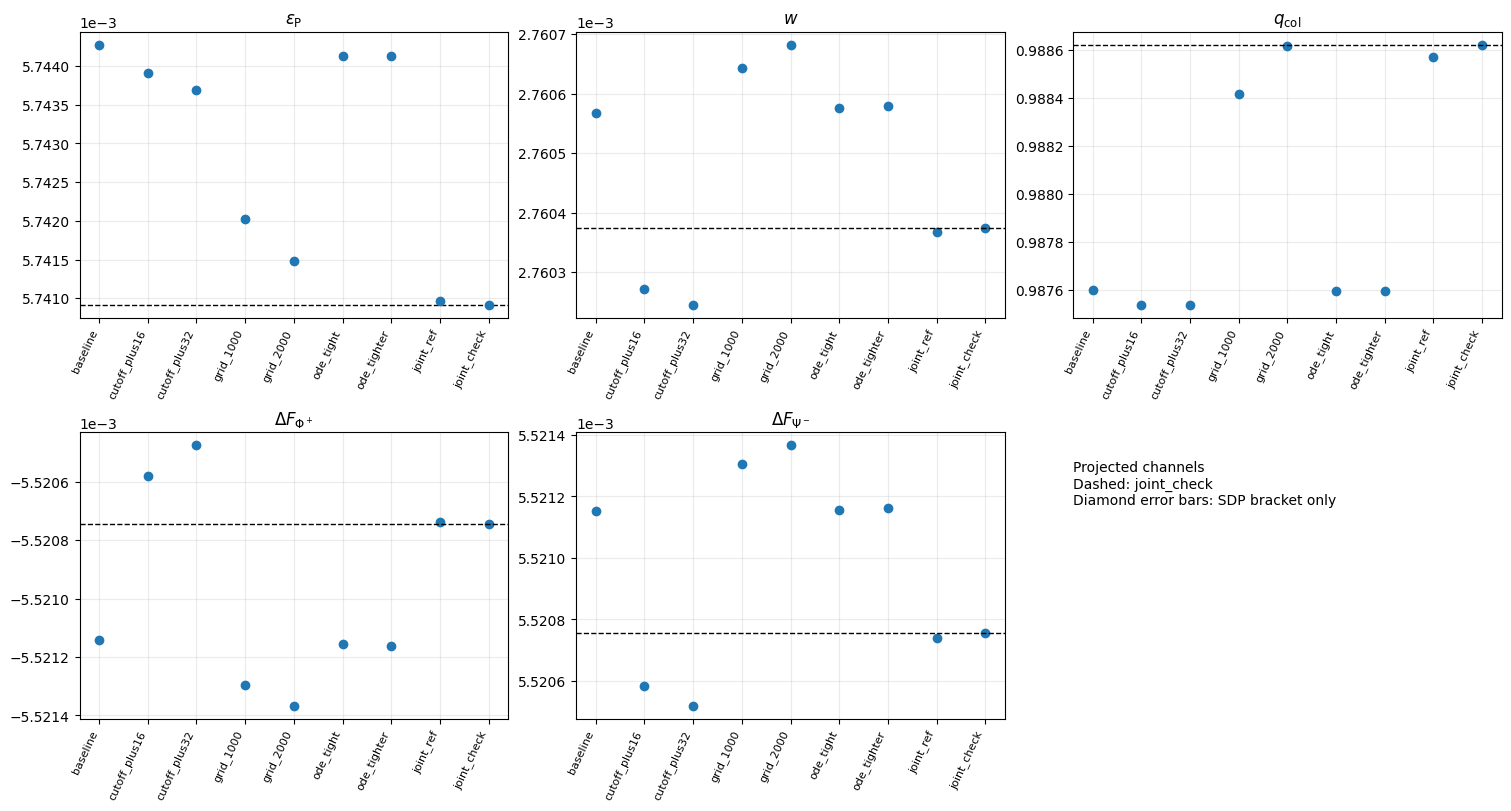

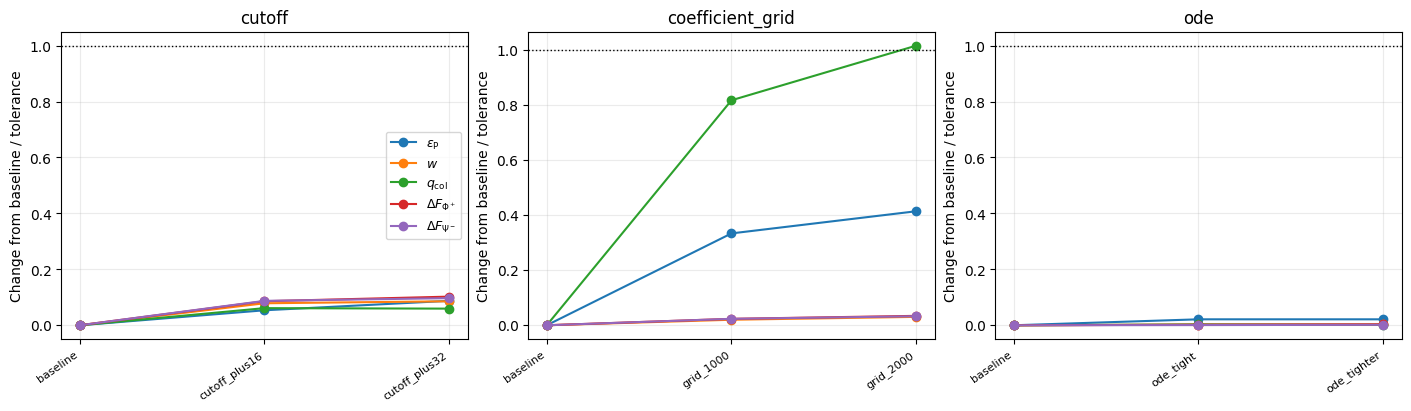

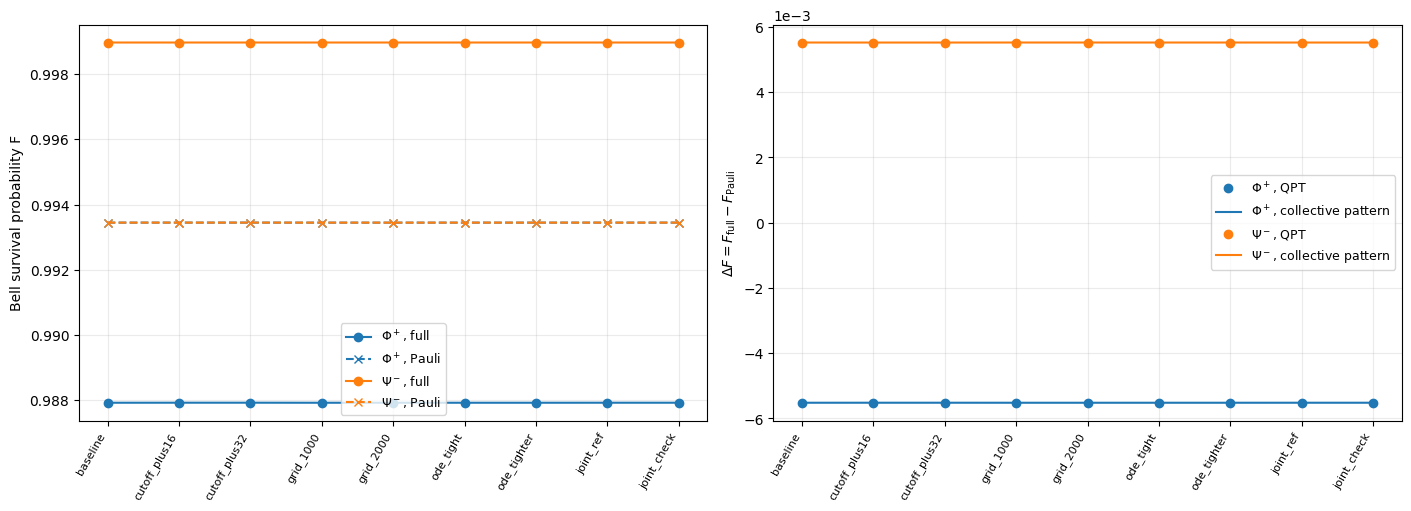

In [18]:
def save_figure(fig, stem):
    fig.savefig(ANALYSIS_DIR / f"{stem}.png", dpi=180, bbox_inches="tight")
    fig.savefig(ANALYSIS_DIR / f"{stem}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)

if metrics.empty:
    print("図は計算後に作成します。")
else:
    projected = metrics.loc[metrics.stage.eq("projected")].set_index("case_id")
    order = [c["case_id"] for c in CASES if c["case_id"] in projected.index]
    projected = projected.loc[order]
    x = np.arange(len(projected))
    plot_metrics = ["epsilon_P", "w", "q_col", "delta_F_phi_plus", "delta_F_psi_minus"]
    titles = [r"$\epsilon_{\rm P}$", r"$w$", r"$q_{\rm col}$",
              r"$\Delta F_{\Phi^+}$", r"$\Delta F_{\Psi^-}$"]
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
    for ax, name, title in zip(axes.flat, plot_metrics, titles):
        if name == "epsilon_P":
            y = projected[name].to_numpy()
            errors = np.maximum(0, np.vstack([
                y - projected["diamond_sdp_lower"].to_numpy(),
                projected["diamond_sdp_upper"].to_numpy() - y,
            ]))
            ax.errorbar(x, y, yerr=errors, fmt="o", capsize=3)
        else:
            ax.plot(x, projected[name], "o")
        if REFERENCE_CASE in projected.index:
            ax.axhline(projected.loc[REFERENCE_CASE, name], color="black", ls="--", lw=1)
        ax.set_title(title)
        ax.set_xticks(x)
        ax.set_xticklabels(order, rotation=65, ha="right", fontsize=8)
        ax.grid(alpha=0.25)
        ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2), useOffset=False)
    axes.flat[-1].axis("off")
    axes.flat[-1].text(0, 0.9, "Projected channels\nDashed: joint_check\n"
                              "Diamond error bars: SDP bracket only",
                      transform=axes.flat[-1].transAxes, va="top")
    save_figure(fig, "convergence_metrics")

    if "baseline" in projected.index:
        fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
        for ax, axis_name, case_ids in zip(
            axes, ("cutoff", "coefficient_grid", "ode"),
            (["baseline", "cutoff_plus16", "cutoff_plus32"],
             ["baseline", "grid_1000", "grid_2000"],
             ["baseline", "ode_tight", "ode_tighter"]),
        ):
            ids = [key for key in case_ids if key in projected.index]
            for name, title in zip(plot_metrics, titles):
                atol, rtol = CHECK_LIMITS[name]
                denominator = atol + rtol * abs(projected.loc["baseline", name])
                change = abs(projected.loc[ids, name] - projected.loc["baseline", name])
                ax.plot(range(len(ids)), change / denominator, "o-", label=title)
            ax.axhline(1, color="black", ls=":", lw=1)
            ax.set_xticks(range(len(ids)))
            ax.set_xticklabels(ids, rotation=35, ha="right", fontsize=8)
            ax.set_title(axis_name)
            ax.set_ylabel("Change from baseline / tolerance")
            ax.grid(alpha=0.25)
        axes[0].legend(fontsize=9)
        save_figure(fig, "single_axis_changes")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
    for name, label, color in (("phi_plus", r"$\Phi^+$", "tab:blue"),
                                ("psi_minus", r"$\Psi^-$", "tab:orange")):
        axes[0].plot(x, projected[f"F_{name}_full"], "o-", color=color, label=f"{label}, full")
        axes[0].plot(x, projected[f"F_{name}_pauli"], "x--", color=color, label=f"{label}, Pauli")
        axes[1].plot(x, projected[f"delta_F_{name}"], "o", color=color, label=f"{label}, QPT")
        axes[1].plot(x, projected[f"collective_delta_F_{name}"], "-", color=color,
                     label=f"{label}, collective pattern")
    for ax in axes:
        ax.set_xticks(x)
        ax.set_xticklabels(order, rotation=60, ha="right", fontsize=8)
        ax.grid(alpha=0.25)
        ax.legend(fontsize=9)
        ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2), useOffset=False)
    axes[0].set_ylabel("Bell survival probability F")
    axes[1].set_ylabel(r"$\Delta F = F_{\rm full}-F_{\rm Pauli}$")
    save_figure(fig, "bell_survival_convergence")


## 9. 判定と本文への反映

全 9 条件について、射影前後の指標が joint_check と指定の目安で一致し、
射影の影響が小さく、CPTP 射影・SDP の検証を通過した場合に、
**今回の数値設定の範囲では安定**と判定する。欠測は合格に数えない。
不合格なら、変化した指標とスキャン軸を確認し、その軸をさらに細かくする。

「$q_{\rm col}$ が約 97–99%」「Bell 予測差が $10^{-3}$ 程度」という値域と、
数値収束の判定は別々に表示する。狭い値域に入っているだけでは収束としない。
ここでは $\bar n=4$ の約 98.8% を検証し、低温側の約 96.6% の収束は検証しない。

本文の数値は、旧結果と新しい収束結果の差を確認してから更新する。
同じ QPT 内での Bell 差と $\mp2w$ の小さな残差を、
計算全体の誤差上限として報告しない。

加えて、raw チャネルの TP 誤差と出力時刻上の trace drift を既定で $10^{-8}$ 以下、
射影前後の半 diamond 距離の解析的上限を $10^{-6}$ 以下とする。
これらの診断目安も設定セルで変更できる。

In [19]:
report = {
    "reference_case": REFERENCE_CASE, "limits": CHECK_LIMITS,
    "scope": "nbar=4, fixed calibrated amplitude; empirical numerical stability only",
    "status": "incomplete",
    "raw_trace_tol": RAW_TRACE_TOL, "projection_distance_tol": PROJECTION_DISTANCE_TOL,
}
required_pairs = {(c["case_id"], stage) for c in CASES for stage in ("raw", "projected")}
available_pairs = set() if metrics.empty else set(zip(metrics.case_id, metrics.stage))
complete = available_pairs == required_pairs
report["complete"] = complete
report["missing_pairs"] = sorted(required_pairs - available_pairs)
if not metrics.empty:
    display(metrics.loc[metrics.stage.eq("raw"), [
        "case_id", "thermal_tail_initial", "top5_population_max_sampled",
        "trace_drift_max_sampled", "choi_min_eigenvalue", "choi_tp_frobenius_error",
        "raw_choi_hermiticity_error", "projection_half_diamond_upper",
    ]])
    reference = metrics.loc[
        metrics.case_id.eq(REFERENCE_CASE) & metrics.stage.eq("projected")
    ]
    if len(reference) == 1:
        ref = reference.iloc[0]
        report["reference_values"] = {name: float(ref[name]) for name in CHECK_LIMITS}
        report["q_col_percent"] = float(100 * ref["q_col"])
        report["q_col_in_97_to_99_percent_band"] = bool(0.97 <= ref["q_col"] <= 0.99)
        report["bell_abs_differences"] = {
            name: abs(float(ref[f"delta_F_{name}"])) for name in BELL_STATES
        }
        display(pd.Series({
            "q_col (%)": 100 * ref["q_col"],
            "|Delta F Phi+|": abs(ref["delta_F_phi_plus"]),
            "|Delta F Psi-|": abs(ref["delta_F_psi_minus"]),
            "Bell attribution residual Phi+": ref["bell_residual_phi_plus"],
            "Bell attribution residual Psi-": ref["bell_residual_psi_minus"],
        }, name="joint_check").to_frame())

if complete and not comparisons.empty:
    reference_checks = comparisons.loc[comparisons.comparison.eq("versus_reference")]
    projection_checks = comparisons.loc[comparisons.comparison.eq("projection_shift")]
    comparison_complete = (
        len(reference_checks) == (len(CASES) - 1) * 2 * len(CHECK_LIMITS)
        and len(projection_checks) == len(CASES) * len(CHECK_LIMITS)
    )
    diagnostics_ok = bool(
        metrics["projection_ok"].all() and metrics["metrics_ok"].all()
        and metrics.loc[metrics.stage.eq("projected"), "cptp_within_tolerance"].all()
        and (metrics["trace_drift_max_sampled"] <= RAW_TRACE_TOL).all()
        and (metrics.loc[metrics.stage.eq("raw"), "choi_tp_frobenius_error"] <= RAW_TRACE_TOL).all()
        and (metrics["projection_half_diamond_upper"] <= PROJECTION_DISTANCE_TOL).all()
    )
    stable = bool(comparison_complete and diagnostics_ok and comparisons["passed"].all())
    report.update(
        status="stable_within_tested_settings" if stable else "needs_refinement",
        comparison_complete=comparison_complete, diagnostics_ok=diagnostics_ok,
        all_reference_metrics_pass=bool(reference_checks["passed"].all()),
        all_projection_shifts_pass=bool(projection_checks["passed"].all()),
    )
    if stable:
        display(Markdown("**全条件が指定した安定性の目安を満たしました。** "
                         "固定した物理条件と検証した数値設定の範囲に限る結論です。"))
    else:
        display(Markdown("**追加の精密化が必要です。** 次の差分または診断を確認してください。"))
        display(comparisons.loc[~comparisons["passed"]])
else:
    display(Markdown("**判定保留：全条件の計算・後処理が完了していません。**"))
atomic_json(ANALYSIS_DIR / "convergence_report.json", report)
pd.DataFrame([{
    "status": report["status"], "complete": report["complete"],
    "reference_case": REFERENCE_CASE, "analysis_dir": str(ANALYSIS_DIR),
}]).to_csv(ANALYSIS_DIR / "report_status.csv", index=False)
print("Report:", ANALYSIS_DIR / "convergence_report.json")


,case_id,thermal_tail_initial,top5_population_max_sampled,trace_drift_max_sampled,choi_min_eigenvalue,choi_tp_frobenius_error,raw_choi_hermiticity_error,projection_half_diamond_upper
0,baseline,3.213876e-07,2.634005e-06,3.441691e-15,-2.922863e-08,4.555012e-15,1.279231e-15,1.423313e-08
2,cutoff_plus16,9.046257e-09,7.467439e-08,3.330669e-15,-2.937201e-07,6.287608e-15,1.284515e-15,1.416871e-07
4,cutoff_plus32,2.546295e-10,1.963617e-09,3.885781e-15,8.985367e-08,5.599944e-15,1.640081e-14,1.965251e-15
6,grid_1000,3.213876e-07,2.634052e-06,2.553513e-15,1.184419e-07,4.507163e-15,1.901772e-15,1.893262e-15
8,grid_2000,3.213876e-07,2.634066e-06,2.220446e-15,2.132087e-07,5.021785e-15,1.578175e-15,2.004437e-15
10,ode_tight,3.213876e-07,2.634004e-06,3.330669e-15,2.131789e-07,8.246137e-15,1.741880e-15,3.051151e-15
12,ode_tighter,3.213876e-07,2.634004e-06,3.774758e-15,2.159456e-07,5.517154e-15,3.159991e-15,2.429939e-15
14,joint_ref,2.546295e-10,1.963041e-09,5.107026e-15,2.160114e-07,1.794856e-14,1.492342e-15,6.102289e-15
16,joint_check,7.167183e-12,4.842743e-11,3.441691e-15,1.194829e-07,5.013127e-15,6.210726e-12,1.811051e-15


,joint_check
q_col (%),9.886205e+01
|Delta F Phi+|,5.520744e-03
|Delta F Psi-|,5.520755e-03
Bell attribution residual Phi+,3.201628e-09
Bell attribution residual Psi-,7.743209e-09


**追加の精密化が必要です。** 次の差分または診断を確認してください。

,comparison,stage,pair,metric,value,reference,abs_change,relative_change,change_including_sdp_bracket,allowed_change,ratio_to_limit,passed
2,versus_reference,raw,baseline,q_col,0.987599,0.988620,0.001021,0.001033,0.001021,0.001000,1.021104,False
11,versus_reference,raw,cutoff_plus16,q_col,0.987538,0.988620,0.001082,0.001095,0.001082,0.001000,1.082346,False
20,versus_reference,raw,cutoff_plus32,q_col,0.987540,0.988620,0.001081,0.001093,0.001081,0.001000,1.080616,False
32,versus_reference,raw,grid_1000,F_phi_plus_full,0.987925,0.987926,0.000001,0.000001,0.000001,0.000001,1.102343,False
41,versus_reference,raw,grid_2000,F_phi_plus_full,0.987925,0.987926,0.000001,0.000001,0.000001,0.000001,1.234017,False
47,versus_reference,raw,ode_tight,q_col,0.987596,0.988620,0.001024,0.001036,0.001024,0.001000,1.024022,False
56,versus_reference,raw,ode_tighter,q_col,0.987598,0.988620,0.001022,0.001034,0.001022,0.001000,1.022342,False
74,versus_reference,projected,baseline,q_col,0.987599,0.988620,0.001021,0.001033,0.001021,0.001000,1.021104,False
83,versus_reference,projected,cutoff_plus16,q_col,0.987538,0.988620,0.001082,0.001095,0.001082,0.001000,1.082345,False
92,versus_reference,projected,cutoff_plus32,q_col,0.987540,0.988620,0.001081,0.001093,0.001081,0.001000,1.080616,False


Report: /Users/hirainoa/Desktop/量子/project/Moon_shot__高橋PJ/MS_gate_Hirai/results/calibrated_channel_convergence_nbar4/49b960c6d512be28/analysis_c88e928392a2/convergence_report.json
